# 08 · Risk diagnostics

## Purpose

This notebook extends the existing backtest by examining:

1. when dealer shortfalls and decision costs accumulate over time;
2. whether the selected R2 rolling-percentile rule achieves its intended coverage;
3. whether underwater events cluster into consecutive periods.

The headline setting uses:

- a two-round purchase horizon (`h = 2`);
- a cost ratio of `k = 4`;
- the corresponding 80th percentile (`tau = 0.8`).

The main comparison covers:

- R0: no buffer;
- R1: fixed 5% buffer;
- R2: selected rolling-percentile rule;
- R4: feature-based quantile regression.

Confirmatory coverage results will focus on the untouched 2020–2026 test period.

In [8]:
import sys
import warnings
from pathlib import Path
from matplotlib.ticker import FuncFormatter

sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import *
from src.backtest import rule_buffers
from src.plots import RULE_COLORS, save, sgd

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

print("Project root:", ROOT)
print("Headline horizon:", H)

Project root: /Users/zipengxu/Documents/guaranteed-coe-pricing
Headline horizon: 2


In [2]:
fc = pd.read_csv(PROC / "forecasts.csv")

EXTRA = {
    "R5 GBM (stretch)": "M4",
    "R6 Combo M1+M3": "M5",
}

bt = rule_buffers(fc, h=H, extra=EXTRA)

rule_counts = bt.groupby("rule").size()

print("Forecast rows:", len(fc))
print("Backtest rows:", len(bt))
print("Quote period:", bt["month"].min(), "to", bt["month"].max())
display(rule_counts)

Forecast rows: 114156
Backtest rows: 28608
Quote period: 2014-01 to 2026-09


rule
R0 No buffer              894
R1 Fixed 5%               894
R2 Rolling percentile    5364
R3 Newsvendor SARIMAX    5364
R4 Newsvendor QR         5364
R5 GBM (stretch)         5364
R6 Combo M1+M3           5364
dtype: int64

In [3]:
HEADLINE_TAU = 0.8
HEADLINE_K = 4

RULES = [
    "R0 No buffer",
    "R1 Fixed 5%",
    "R2 Rolling percentile",
    "R4 Newsvendor QR",
]

headline = bt[
    bt["rule"].isin(RULES)
    & (bt["tau"].isna() | (bt["tau"] == HEADLINE_TAU))
].copy()

headline["shortfall"] = (
    headline["actual_sgd"] - headline["buffer"]
).clip(lower=0)

headline["excess"] = (
    headline["buffer"] - headline["actual_sgd"]
).clip(lower=0)

headline["underwater"] = headline["shortfall"] > 0

headline["decision_cost"] = (
    headline["shortfall"]
    + headline["excess"] / HEADLINE_K
)

print("Selected rows:", len(headline))
print(headline.groupby("rule").size())

Selected rows: 3576
rule
R0 No buffer             894
R1 Fixed 5%              894
R2 Rolling percentile    894
R4 Newsvendor QR         894
dtype: int64


In [4]:
summary = (
    headline.groupby("rule")
    .agg(
        n=("shortfall", "size"),
        underwater_pct=("underwater", lambda x: x.mean() * 100),
        avg_buffer=("buffer", "mean"),
        avg_shortfall_all_cars=("shortfall", "mean"),
        avg_excess=("excess", "mean"),
        avg_decision_cost=("decision_cost", "mean"),
    )
)

display(summary.round(1))

,n,underwater_pct,avg_buffer,avg_shortfall_all_cars,avg_excess,avg_decision_cost
rule,,,,,,
R0 No buffer,894,54.500,0.000,"2,370.200","2,010.800","2,872.900"
R1 Fixed 5%,894,27.700,"3,647.300",901.900,"4,189.800","1,949.300"
R2 Rolling percentile,894,19.400,"5,306.400",539.700,"5,486.800","1,911.400"
R4 Newsvendor QR,894,18.200,"5,612.200",536.900,"5,789.700","1,984.300"


## Cumulative risk over time

The overall averages do not show when losses occur. We therefore aggregate the
three simulated category sales within each quote round and calculate:

- cumulative dealer shortfall;
- cumulative newsvendor decision cost at `k = 4`;
- cumulative decision-cost savings relative to the fixed 5% rule.

These quantities are simulated backtest outcomes, not the dealer's actual accounting profit.

In [5]:
headline["quote_date"] = (
    pd.to_datetime(headline["month"] + "-01")
    + pd.to_timedelta(
        np.where(headline["bidding_no"] == 1, 6, 20),
        unit="D",
    )
)

roundly = (
    headline.groupby(
        ["rule", "round_id", "quote_date"],
        as_index=False,
    )
    .agg(
        shortfall=("shortfall", "sum"),
        excess=("excess", "sum"),
        decision_cost=("decision_cost", "sum"),
        underwater_sales=("underwater", "sum"),
        number_of_sales=("category", "size"),
    )
    .sort_values(["rule", "round_id"])
)

roundly["cum_shortfall"] = (
    roundly.groupby("rule")["shortfall"].cumsum()
)

roundly["cum_decision_cost"] = (
    roundly.groupby("rule")["decision_cost"].cumsum()
)

print("Rows per rule:")
display(roundly.groupby("rule").size())

print("First five rows:")
display(roundly.head())

Rows per rule:


rule
R0 No buffer             298
R1 Fixed 5%              298
R2 Rolling percentile    298
R4 Newsvendor QR         298
dtype: int64

First five rows:


,rule,round_id,quote_date,shortfall,excess,decision_cost,underwater_sales,number_of_sales,cum_shortfall,cum_decision_cost
0,R0 No buffer,96,2014-01-07,0.000,"6,202.000","1,550.500",0,3,0.000,"1,550.500"
1,R0 No buffer,97,2014-01-21,"5,101.000",396.000,"5,200.000",2,3,"5,101.000","6,750.500"
2,R0 No buffer,98,2014-02-07,"15,842.000",0.000,"15,842.000",3,3,"20,943.000","22,592.500"
3,R0 No buffer,99,2014-02-21,"10,698.000",0.000,"10,698.000",3,3,"31,641.000","33,290.500"
4,R0 No buffer,100,2014-03-07,"6,295.000",0.000,"6,295.000",3,3,"37,936.000","39,585.500"


In [6]:
final_cumulative = (
    roundly.groupby("rule")
    .agg(
        total_shortfall=("shortfall", "sum"),
        total_excess=("excess", "sum"),
        total_decision_cost=("decision_cost", "sum"),
        underwater_sales=("underwater_sales", "sum"),
        total_sales=("number_of_sales", "sum"),
    )
)

final_cumulative["underwater_pct"] = (
    final_cumulative["underwater_sales"]
    / final_cumulative["total_sales"]
    * 100
)

display(final_cumulative.round(0))

,total_shortfall,total_excess,total_decision_cost,underwater_sales,total_sales,underwater_pct
rule,,,,,,
R0 No buffer,"2,118,938.000","1,797,688.000","2,568,360.000",487,894,54.000
R1 Fixed 5%,"806,282.000","3,745,677.000","1,742,701.000",248,894,28.000
R2 Rolling percentile,"482,535.000","4,905,162.000","1,708,825.000",173,894,19.000
R4 Newsvendor QR,"479,952.000","5,175,986.000","1,773,948.000",163,894,18.000


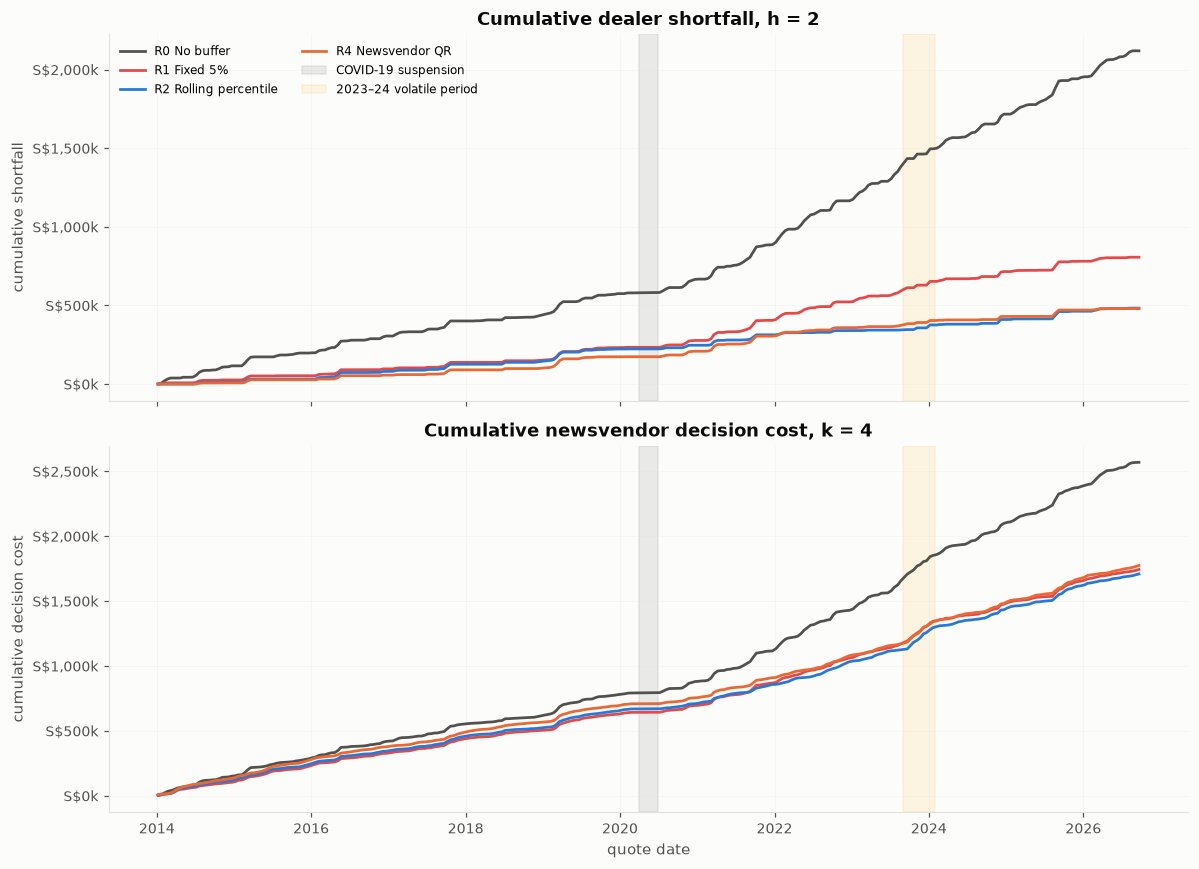

In [9]:
fig, axes = plt.subplots(
    2,
    1,
    figsize=(11, 8),
    sharex=True,
)

for rule in RULES:
    g = roundly[roundly["rule"] == rule]

    axes[0].plot(
        g["quote_date"],
        g["cum_shortfall"],
        label=rule,
        color=RULE_COLORS[rule],
        linewidth=1.8,
    )

    axes[1].plot(
        g["quote_date"],
        g["cum_decision_cost"],
        label=rule,
        color=RULE_COLORS[rule],
        linewidth=1.8,
    )

for ax in axes:
    # COVID-19 bidding suspension
    ax.axvspan(
        pd.Timestamp("2020-04-01"),
        pd.Timestamp("2020-07-01"),
        color="grey",
        alpha=0.15,
        label="COVID-19 suspension",
    )

    # Large premium movements around late 2023 / early 2024
    ax.axvspan(
        pd.Timestamp("2023-09-01"),
        pd.Timestamp("2024-02-01"),
        color="orange",
        alpha=0.10,
        label="2023–24 volatile period",
    )

    ax.grid(alpha=0.25)
    ax.yaxis.set_major_formatter(FuncFormatter(sgd))

axes[0].set_title(
    "Cumulative dealer shortfall, h = 2"
)
axes[0].set_ylabel("cumulative shortfall")

axes[1].set_title(
    "Cumulative newsvendor decision cost, k = 4"
)
axes[1].set_ylabel("cumulative decision cost")
axes[1].set_xlabel("quote date")

# Avoid duplicated shaded-area labels
handles, labels = axes[0].get_legend_handles_labels()
unique = dict(zip(labels, handles))
axes[0].legend(
    unique.values(),
    unique.keys(),
    loc="upper left",
    ncol=2,
    fontsize=8,
)

fig.tight_layout()
save(fig, "08_cumulative_risk.png")
plt.show()

## Cumulative decision-cost savings relative to a fixed 5% buffer

A positive value means that the model rule has accumulated a lower newsvendor
decision cost than the fixed 5% rule. A falling line means that the model rule
performed worse during that period.

The comparison uses the headline cost ratio `k = 4`.

In [10]:
cost_wide = (
    roundly.pivot(
        index=["round_id", "quote_date"],
        columns="rule",
        values="decision_cost",
    )
    .reset_index()
    .sort_values("round_id")
)

for rule in [
    "R0 No buffer",
    "R2 Rolling percentile",
    "R4 Newsvendor QR",
]:
    column_name = f"{rule}_saving_vs_R1"

    cost_wide[column_name] = (
        cost_wide["R1 Fixed 5%"]
        - cost_wide[rule]
    )

    cost_wide[f"cum_{column_name}"] = (
        cost_wide[column_name].cumsum()
    )

final_savings = pd.DataFrame(
    {
        "final_cumulative_saving_vs_R1": {
            rule: cost_wide[
                f"cum_{rule}_saving_vs_R1"
            ].iloc[-1]
            for rule in [
                "R0 No buffer",
                "R2 Rolling percentile",
                "R4 Newsvendor QR",
            ]
        }
    }
)

display(final_savings.round(0))

,final_cumulative_saving_vs_R1
R0 No buffer,"-825,659.000"
R2 Rolling percentile,"33,876.000"
R4 Newsvendor QR,"-31,247.000"


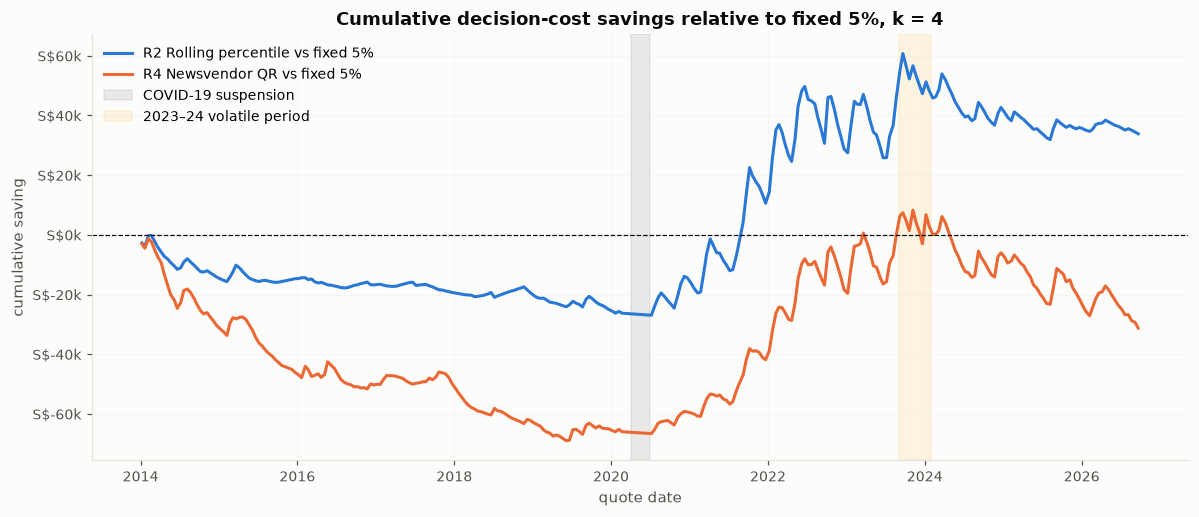

In [11]:
fig, ax = plt.subplots(figsize=(11, 4.8))

for rule in [
    "R2 Rolling percentile",
    "R4 Newsvendor QR",
]:
    ax.plot(
        cost_wide["quote_date"],
        cost_wide[f"cum_{rule}_saving_vs_R1"],
        label=f"{rule} vs fixed 5%",
        color=RULE_COLORS[rule],
        linewidth=2,
    )

ax.axhline(
    0,
    color="black",
    linewidth=0.8,
    linestyle="--",
)

ax.axvspan(
    pd.Timestamp("2020-04-01"),
    pd.Timestamp("2020-07-01"),
    color="grey",
    alpha=0.15,
    label="COVID-19 suspension",
)

ax.axvspan(
    pd.Timestamp("2023-09-01"),
    pd.Timestamp("2024-02-01"),
    color="orange",
    alpha=0.10,
    label="2023–24 volatile period",
)

ax.set_title(
    "Cumulative decision-cost savings relative to fixed 5%, k = 4"
)
ax.set_xlabel("quote date")
ax.set_ylabel("cumulative saving")
ax.yaxis.set_major_formatter(FuncFormatter(sgd))
ax.grid(alpha=0.25)
ax.legend(loc="best")

fig.tight_layout()
save(fig, "08_cumulative_saving_vs_fixed5.png")
plt.show()

In [12]:
period_cost = (
    headline.groupby(["period", "rule"])["decision_cost"]
    .sum()
    .unstack("rule")
)

period_comparison = pd.DataFrame(
    {
        "R1 Fixed 5% cost": period_cost["R1 Fixed 5%"],
        "R2 cost": period_cost["R2 Rolling percentile"],
        "R2 saving vs R1": (
            period_cost["R1 Fixed 5%"]
            - period_cost["R2 Rolling percentile"]
        ),
        "R4 cost": period_cost["R4 Newsvendor QR"],
        "R4 saving vs R1": (
            period_cost["R1 Fixed 5%"]
            - period_cost["R4 Newsvendor QR"]
        ),
    }
)

display(period_comparison.round(0))

,R1 Fixed 5% cost,R2 cost,R2 saving vs R1,R4 cost,R4 saving vs R1
period,,,,,
2014-19,"627,822.000","652,806.000","-24,984.000","692,824.000","-65,001.000"
2020-22,"433,125.000","379,358.000","53,766.000","386,441.000","46,684.000"
2023-26,"681,754.000","676,660.000","5,094.000","694,683.000","-12,929.000"


## Kupiec unconditional coverage test

For a forecast quantile `tau`, an underwater event occurs when the actual
two-round COE rise exceeds the buffer.

At `tau = 0.8`, the expected underwater probability is:

\[
p_0 = 1 - \tau = 0.2.
\]

The Kupiec test evaluates:

\[
H_0: p = 0.2
\]

against the alternative that the true underwater probability differs from 0.2.

A p-value below 0.05 indicates that the observed underwater frequency is
inconsistent with the intended quantile coverage.

Formal tests are performed separately by COE category because categories in the
same bidding round may experience common market shocks.

In [13]:
from scipy.stats import chi2


def kupiec_test(exceptions, expected_exception_rate):
    """
    Kupiec unconditional coverage test.

    exceptions:
        Array containing 1 for underwater and 0 otherwise.

    expected_exception_rate:
        The intended probability of being underwater, equal to 1 - tau.
    """
    exceptions = np.asarray(exceptions, dtype=int)

    n = len(exceptions)
    x = int(exceptions.sum())

    if n == 0:
        return {
            "n": 0,
            "exceptions": 0,
            "expected_exceptions": np.nan,
            "exception_rate": np.nan,
            "lr_uc": np.nan,
            "p_value": np.nan,
        }

    p0 = expected_exception_rate
    p_hat = x / n

    # Avoid log(0) if there are zero or n exceptions.
    eps = 1e-12
    p_hat_safe = np.clip(p_hat, eps, 1 - eps)

    log_likelihood_null = (
        x * np.log(p0)
        + (n - x) * np.log(1 - p0)
    )

    log_likelihood_observed = (
        x * np.log(p_hat_safe)
        + (n - x) * np.log(1 - p_hat_safe)
    )

    lr_uc = -2 * (
        log_likelihood_null
        - log_likelihood_observed
    )

    p_value = chi2.sf(lr_uc, df=1)

    return {
        "n": n,
        "exceptions": x,
        "expected_exceptions": n * p0,
        "exception_rate": p_hat,
        "lr_uc": lr_uc,
        "p_value": p_value,
    }

In [14]:
COVERAGE_RULES = [
    "R2 Rolling percentile",
    "R4 Newsvendor QR",
]

coverage_data = bt[
    bt["rule"].isin(COVERAGE_RULES)
    & (bt["tau"] == HEADLINE_TAU)
].copy()

coverage_data["exception"] = (
    coverage_data["actual_sgd"]
    > coverage_data["buffer"]
).astype(int)

print("Rows by rule and category:")
display(
    coverage_data.groupby(["rule", "category"])
    .size()
    .unstack("category")
)

Rows by rule and category:


category,A,B,E
rule,,,
R2 Rolling percentile,298,298,298
R4 Newsvendor QR,298,298,298


In [15]:
EXPECTED_EXCEPTION_RATE = 1 - HEADLINE_TAU

samples = {
    "Full 2014-26": coverage_data.index == coverage_data.index,
    "Test 2020-26": coverage_data["period"].isin(TEST_PERIODS),
}

kupiec_rows = []

for sample_name, sample_mask in samples.items():
    sample_data = coverage_data[sample_mask]

    for rule in COVERAGE_RULES:
        for category in ["A", "B", "E"]:
            g = sample_data[
                (sample_data["rule"] == rule)
                & (sample_data["category"] == category)
            ]

            result = kupiec_test(
                g["exception"],
                EXPECTED_EXCEPTION_RATE,
            )

            kupiec_rows.append(
                {
                    "sample": sample_name,
                    "rule": rule,
                    "category": category,
                    "tau": HEADLINE_TAU,
                    "target_exception_rate": EXPECTED_EXCEPTION_RATE,
                    **result,
                }
            )

kupiec_results = pd.DataFrame(kupiec_rows)

kupiec_results["exception_rate_pct"] = (
    kupiec_results["exception_rate"] * 100
)

kupiec_results["reject_5pct"] = (
    kupiec_results["p_value"] < 0.05
)

display(
    kupiec_results[
        [
            "sample",
            "rule",
            "category",
            "n",
            "exceptions",
            "expected_exceptions",
            "exception_rate_pct",
            "lr_uc",
            "p_value",
            "reject_5pct",
        ]
    ].round(3)
)

,sample,rule,category,n,exceptions,expected_exceptions,exception_rate_pct,lr_uc,p_value,reject_5pct
0,Full 2014-26,R2 Rolling percentile,A,298,57,59.600,19.128,0.143,0.705,False
1,Full 2014-26,R2 Rolling percentile,B,298,58,59.600,19.463,0.054,0.816,False
2,Full 2014-26,R2 Rolling percentile,E,298,58,59.600,19.463,0.054,0.816,False
3,Full 2014-26,R4 Newsvendor QR,A,298,51,59.600,17.114,1.612,0.204,False
4,Full 2014-26,R4 Newsvendor QR,B,298,54,59.600,18.121,0.674,0.412,False
5,Full 2014-26,R4 Newsvendor QR,E,298,58,59.600,19.463,0.054,0.816,False
6,Test 2020-26,R2 Rolling percentile,A,154,31,30.800,20.130,0.002,0.968,False
7,Test 2020-26,R2 Rolling percentile,B,154,26,30.800,16.883,0.975,0.323,False
8,Test 2020-26,R2 Rolling percentile,E,154,27,30.800,17.532,0.605,0.437,False
9,Test 2020-26,R4 Newsvendor QR,A,154,32,30.800,20.779,0.058,0.810,False


In [16]:
kupiec_results.to_csv(
    PROC / "kupiec_coverage_tests.csv",
    index=False,
)

print(
    "Saved:",
    PROC / "kupiec_coverage_tests.csv",
)

Saved: /Users/zipengxu/Documents/guaranteed-coe-pricing/data/processed/kupiec_coverage_tests.csv


## Christoffersen independence test

The Kupiec test checks whether the overall exception rate equals 20%.
The Christoffersen independence test checks whether exceptions cluster over time.

Because the forecast horizon is h = 2, adjacent forecast outcomes overlap.
We therefore split each category into two non-overlapping paths:
even-numbered and odd-numbered forecast origins.

In [17]:
def christoffersen_independence_test(exceptions):
    x = np.asarray(exceptions, dtype=int)

    if len(x) < 2:
        return {
            "n": len(x),
            "n00": np.nan,
            "n01": np.nan,
            "n10": np.nan,
            "n11": np.nan,
            "exception_after_safe_pct": np.nan,
            "exception_after_exception_pct": np.nan,
            "lr_ind": np.nan,
            "p_value": np.nan,
        }

    previous = x[:-1]
    current = x[1:]

    n00 = int(((previous == 0) & (current == 0)).sum())
    n01 = int(((previous == 0) & (current == 1)).sum())
    n10 = int(((previous == 1) & (current == 0)).sum())
    n11 = int(((previous == 1) & (current == 1)).sum())

    total_0 = n00 + n01
    total_1 = n10 + n11
    total = n00 + n01 + n10 + n11

    pi_0 = n01 / total_0 if total_0 > 0 else np.nan
    pi_1 = n11 / total_1 if total_1 > 0 else np.nan
    pi = (n01 + n11) / total if total > 0 else np.nan

    eps = 1e-12

    def log_term(count, probability):
        if count == 0:
            return 0.0
        probability = np.clip(probability, eps, 1 - eps)
        return count * np.log(probability)

    if np.isnan(pi_0) or np.isnan(pi_1):
        lr_ind = np.nan
        p_value = np.nan
    else:
        ll_independent = (
            log_term(n00 + n10, 1 - pi)
            + log_term(n01 + n11, pi)
        )

        ll_markov = (
            log_term(n00, 1 - pi_0)
            + log_term(n01, pi_0)
            + log_term(n10, 1 - pi_1)
            + log_term(n11, pi_1)
        )

        lr_ind = -2 * (ll_independent - ll_markov)
        p_value = chi2.sf(lr_ind, df=1)

    return {
        "n": len(x),
        "n00": n00,
        "n01": n01,
        "n10": n10,
        "n11": n11,
        "exception_after_safe_pct": pi_0 * 100,
        "exception_after_exception_pct": pi_1 * 100,
        "lr_ind": lr_ind,
        "p_value": p_value,
    }

In [18]:
christoffersen_rows = []

for sample_name, mask in samples.items():
    sample_data = coverage_data[mask].copy()

    for rule in COVERAGE_RULES:
        for category in ["A", "B", "E"]:
            g = (
                sample_data[
                    (sample_data.rule == rule)
                    & (sample_data.category == category)
                ]
                .sort_values("round_id")
                .copy()
            )

            g["path"] = g["round_id"].astype(int) % H

            for path in [0, 1]:
                path_data = g[g.path == path].sort_values("round_id")

                result = christoffersen_independence_test(
                    path_data.exception
                )

                christoffersen_rows.append({
                    "sample": sample_name,
                    "rule": rule,
                    "category": category,
                    "path": path,
                    **result,
                })

christoffersen_results = pd.DataFrame(christoffersen_rows)

christoffersen_results["reject_5pct"] = (
    christoffersen_results.p_value < 0.05
)

display(
    christoffersen_results.round(3)
)

christoffersen_results.to_csv(
    PROC / "christoffersen_independence_tests.csv",
    index=False
)

,sample,rule,category,path,n,n00,n01,n10,n11,exception_after_safe_pct,exception_after_exception_pct,lr_ind,p_value,reject_5pct
0,Full 2014-26,R2 Rolling percentile,A,0,149,90,26,26,6,22.414,18.750,0.204,0.652,False
1,Full 2014-26,R2 Rolling percentile,A,1,149,101,22,22,3,17.886,12.000,0.550,0.458,False
2,Full 2014-26,R2 Rolling percentile,B,0,149,90,25,25,8,21.739,24.242,0.091,0.762,False
3,Full 2014-26,R2 Rolling percentile,B,1,149,103,20,20,5,16.260,20.000,0.200,0.655,False
4,Full 2014-26,R2 Rolling percentile,E,0,149,88,25,25,10,22.124,28.571,0.597,0.440,False
5,Full 2014-26,R2 Rolling percentile,E,1,149,107,18,18,5,14.400,21.739,0.739,0.390,False
6,Full 2014-26,R4 Newsvendor QR,A,0,149,101,21,21,5,17.213,19.231,0.059,0.808,False
7,Full 2014-26,R4 Newsvendor QR,A,1,149,104,19,19,6,15.447,24.000,1.004,0.316,False
8,Full 2014-26,R4 Newsvendor QR,B,0,149,90,25,25,8,21.739,24.242,0.091,0.762,False
9,Full 2014-26,R4 Newsvendor QR,B,1,149,111,16,16,5,12.598,23.810,1.644,0.200,False


In [19]:
number_of_tests = len(christoffersen_results)

christoffersen_results["p_bonferroni"] = (
    christoffersen_results["p_value"] * number_of_tests
).clip(upper=1)

christoffersen_results["reject_bonferroni_5pct"] = (
    christoffersen_results["p_bonferroni"] < 0.05
)

significant_results = christoffersen_results[
    christoffersen_results["reject_5pct"]
][[
    "sample",
    "rule",
    "category",
    "path",
    "exception_after_safe_pct",
    "exception_after_exception_pct",
    "p_value",
    "p_bonferroni",
    "reject_bonferroni_5pct",
]]

display(significant_results.round(3))

,sample,rule,category,path,exception_after_safe_pct,exception_after_exception_pct,p_value,p_bonferroni,reject_bonferroni_5pct
11,Full 2014-26,R4 Newsvendor QR,E,1,12.295,42.308,0.001,0.020,True
23,Test 2020-26,R4 Newsvendor QR,E,1,14.754,40.000,0.039,0.933,False


In [20]:
christoffersen_results.to_csv(
    PROC / "christoffersen_independence_tests.csv",
    index=False
)

print(
    "Saved:",
    PROC / "christoffersen_independence_tests.csv"
)

Saved: /Users/zipengxu/Documents/guaranteed-coe-pricing/data/processed/christoffersen_independence_tests.csv


## Final findings

This notebook adds two risk diagnostics to the original backtest.

### 1. Cumulative dealer risk

At the headline setting of \(h=2\), \(\tau=0.8\), and \(k=4\):

- R0 No buffer produced total shortfall of S$2,118,938 and decision cost of S$2,568,360.
- R1 Fixed 5% produced total shortfall of S$806,282 and decision cost of S$1,742,701.
- R2 Rolling percentile produced total shortfall of S$482,535 and the lowest decision cost of S$1,708,825.
- R4 Newsvendor QR produced slightly lower shortfall of S$479,952, but its larger buffers raised decision cost to S$1,773,948.

Relative to the fixed 5% rule, R2 saved S$33,876 over the full backtest. However, this advantage was not stable in every period. R2 was S$24,984 more costly in 2014–2019, saved S$53,766 in 2020–2022, and saved S$5,094 in 2023–2026.

Therefore, most of R2's cumulative advantage came from the volatile 2020–2022 period.

### 2. Unconditional coverage

The Kupiec tests did not reject the target 20% exception rate for R2 or R4 in any category, over either the full 2014–2026 sample or the 2020–2026 test period.

This means that both methods achieved acceptable overall coverage. It does not, by itself, show that exceptions were independent over time.

### 3. Exception clustering

Because the forecast horizon is two rounds, forecast origins were divided into two non-overlapping paths before applying the Christoffersen independence test.

No significant exception clustering was found for R2 in Category A, B, or E.

For R4 Category E, path 1 showed evidence of clustering:

- Over 2014–2026, the exception probability was 12.3% after a safe outcome and 42.3% after an exception. The original p-value was 0.001 and the Bonferroni-adjusted p-value was 0.020.
- Over the 2020–2026 test period, the corresponding probabilities were 14.8% and 40.0%. The original p-value was 0.039, but the Bonferroni-adjusted p-value was 0.933.

The full-sample result remains significant after correction, while the test-period result does not. This should therefore be treated as a risk warning rather than proof that R4 always produces clustered losses.

### Overall conclusion

Under the stated business assumptions, R2 Rolling percentile remains the preferred rule. It achieved approximately the target coverage rate, had no detected exception clustering, and produced the lowest cumulative decision cost at \(k=4\).

The conclusion is conditional on the assumed underpricing-to-overpricing cost ratio, the two-round purchase horizon, and the historical backtest period. R2 should not be described as universally superior under every dealer cost structure or market regime.